# ПР1. Первичный анализ датасета NASA NEO

**Тема проекта:** Система оценки потенциальной опасности астероидов.
**Источник данных:** NASA Asteroid Dataset (Kaggle).
**Выполнил:** [Adylov Arsen]

In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("../data/raw/dataset.csv", low_memory=False)
df.head()

,id,spkid,full_name,pdes,name,prefix,neo,pha,H,diameter,...,sigma_i,sigma_om,sigma_w,sigma_ma,sigma_ad,sigma_n,sigma_tp,sigma_per,class,rms
0,a0000001,2000001,1 Ceres,1,Ceres,NaN,N,N,3.40,939.400,...,4.608900e-09,6.168800e-08,6.624800e-08,7.820700e-09,1.111300e-11,1.196500e-12,3.782900e-08,9.415900e-09,MBA,0.43301
1,a0000002,2000002,2 Pallas,2,Pallas,NaN,N,N,4.20,545.000,...,3.469400e-06,6.272400e-06,9.128200e-06,8.859100e-06,4.961300e-09,4.653600e-10,4.078700e-05,3.680700e-06,MBA,0.35936
2,a0000003,2000003,3 Juno,3,Juno,NaN,N,N,5.33,246.596,...,3.223100e-06,1.664600e-05,1.772100e-05,8.110400e-06,4.363900e-09,4.413400e-10,3.528800e-05,3.107200e-06,MBA,0.33848
3,a0000004,2000004,4 Vesta,4,Vesta,NaN,N,N,3.00,525.400,...,2.170600e-07,3.880800e-07,1.789300e-07,1.206800e-06,1.648600e-09,2.612500e-10,4.103700e-06,1.274900e-06,MBA,0.39980
4,a0000005,2000005,5 Astraea,5,Astraea,NaN,N,N,6.90,106.699,...,2.740800e-06,2.894900e-05,2.984200e-05,8.303800e-06,4.729000e-09,5.522700e-10,3.474300e-05,3.490500e-06,MBA,0.52191


In [2]:
print("Размер таблицы (строк, столбцов):", df.shape)
df.info()

Размер таблицы (строк, столбцов): (958524, 45)
<class 'pandas.DataFrame'>
RangeIndex: 958524 entries, 0 to 958523
Data columns (total 45 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   id              958524 non-null  str    
 1   spkid           958524 non-null  int64  
 2   full_name       958524 non-null  str    
 3   pdes            958524 non-null  str    
 4   name            22064 non-null   str    
 5   prefix          18 non-null      str    
 6   neo             958520 non-null  str    
 7   pha             938603 non-null  str    
 8   H               952261 non-null  float64
 9   diameter        136209 non-null  float64
 10  albedo          135103 non-null  float64
 11  diameter_sigma  136081 non-null  float64
 12  orbit_id        958524 non-null  str    
 13  epoch           958524 non-null  float64
 14  epoch_mjd       958524 non-null  int64  
 15  epoch_cal       958524 non-null  float64
 16  equinox         9585

In [3]:
df.describe()

,spkid,H,diameter,albedo,diameter_sigma,epoch,epoch_mjd,epoch_cal,e,a,...,sigma_q,sigma_i,sigma_om,sigma_w,sigma_ma,sigma_ad,sigma_n,sigma_tp,sigma_per,rms
count,9.585240e+05,952261.000000,136209.000000,135103.000000,136081.000000,9.585240e+05,958524.000000,9.585240e+05,958524.000000,958524.000000,...,9.386020e+05,9.386020e+05,9.386020e+05,9.386020e+05,9.386020e+05,9.385980e+05,9.386020e+05,9.386020e+05,9.385980e+05,958522.000000
mean,3.810114e+06,16.906411,5.506429,0.130627,0.479184,2.458869e+06,58868.781950,2.019693e+07,0.156116,2.902143,...,1.982929e+01,1.168449e+00,5.310234e+00,1.370062e+06,1.369977e+06,2.131453e+01,5.060221e-02,4.312780e+08,8.525815e+04,0.561153
std,6.831541e+06,1.790405,9.425164,0.110323,0.782895,7.016716e+02,701.671573,1.930354e+04,0.092643,39.719503,...,2.903785e+03,1.282231e+02,1.333381e+03,9.158996e+08,9.158991e+08,7.197034e+03,9.814953e+00,2.953046e+11,2.767681e+07,2.745700
min,2.000001e+06,-1.100000,0.002500,0.001000,0.000500,2.425052e+06,25051.000000,1.927062e+07,0.000000,-14702.447872,...,1.956900e-11,4.608900e-09,6.168800e-08,6.624800e-08,7.820700e-09,1.111300e-11,1.196500e-12,3.782900e-08,9.415900e-09,0.000000
25%,2.239632e+06,16.100000,2.780000,0.053000,0.180000,2.459000e+06,59000.000000,2.020053e+07,0.092193,2.387835,...,1.462000e-07,6.095900e-06,3.619400e-05,5.755000e-05,2.573700e-05,2.340900e-08,2.768800e-09,1.110900e-04,1.794500e-05,0.518040
50%,2.479262e+06,16.900000,3.972000,0.079000,0.332000,2.459000e+06,59000.000000,2.020053e+07,0.145002,2.646969,...,2.271900e-07,8.688800e-06,6.642550e-05,1.047100e-04,4.900100e-05,4.359000e-08,4.638000e-09,2.230800e-04,3.501700e-05,0.566280
75%,3.752518e+06,17.714000,5.765000,0.190000,0.620000,2.459000e+06,59000.000000,2.020053e+07,0.200650,3.001932,...,6.583200e-07,1.591500e-05,1.609775e-04,3.114400e-04,1.718900e-04,1.196600e-07,1.124000e-08,8.139600e-04,9.775475e-05,0.613927
max,5.401723e+07,33.200000,939.400000,1.000000,140.000000,2.459000e+06,59000.000000,2.020053e+07,1.855356,33488.895955,...,1.015000e+06,5.533000e+04,1.199100e+06,8.845100e+11,8.845100e+11,5.509700e+06,7.698800e+03,2.853100e+14,1.910700e+10,2686.600000


In [4]:
missing = df.isnull().sum()
missing[missing > 0].sort_values(ascending=False)

prefix            958506
name              936460
albedo            823421
diameter_sigma    822443
diameter          822315
sigma_per          19926
sigma_ad           19926
sigma_i            19922
sigma_q            19922
sigma_om           19922
sigma_ma           19922
sigma_n            19922
sigma_tp           19922
sigma_e            19922
sigma_a            19922
sigma_w            19922
pha                19921
moid               19921
H                   6263
moid_ld              127
neo                    4
ad                     4
per                    4
rms                    2
ma                     1
per_y                  1
dtype: int64

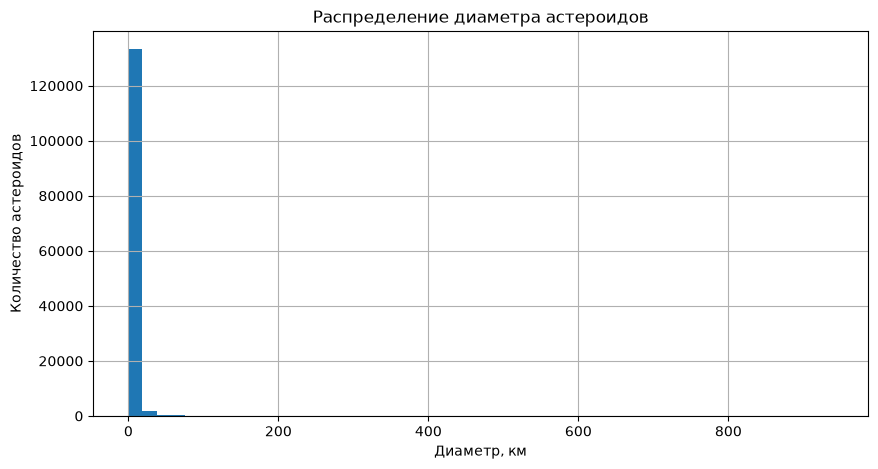

In [5]:
plt.figure(figsize=(10, 5))
df['diameter'].dropna().hist(bins=50)
plt.title("Распределение диаметра астероидов")
plt.xlabel("Диаметр, км")
plt.ylabel("Количество астероидов")
plt.show()

**Вывод по графику:** гистограмма выглядит «одним столбиком» — распределение
диаметра сильно скошено вправо: подавляющее большинство астероидов имеют
диаметр единицы километров, но присутствуют редкие гиганты (до ~940 км,
медиана ~4 км при max 939 км). Выбросы искажают масштаб оси — детальное
исследование распределения и выбросов выполним в ПР2.

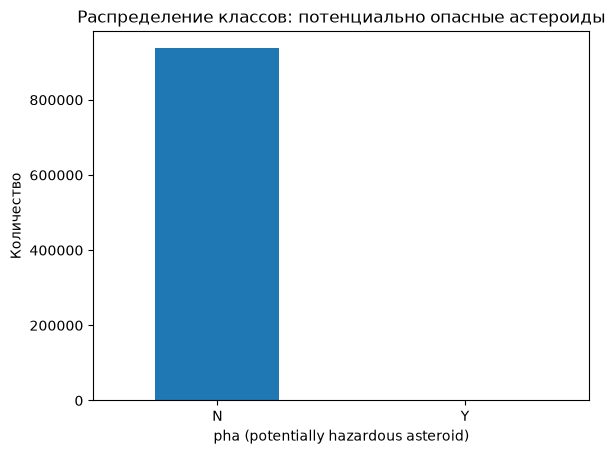

pha
N    936537
Y      2066
Name: count, dtype: int64


In [6]:
pha_counts = df['pha'].value_counts()
pha_counts.plot.bar()
plt.title("Распределение классов: потенциально опасные астероиды")
plt.xlabel("pha (potentially hazardous asteroid)")
plt.ylabel("Количество")
plt.xticks(rotation=0)
plt.show()
print(pha_counts)

## Первичные наблюдения

1. **Размер данных:** в таблице 958 524 строки и 45 столбцов.
2. **Типы данных:** 33 числовых признака (float64), 2 целочисленных, 10 строковых;
   есть как физические параметры (диаметр, альбедо, яркость), так и орбитальные
   элементы и служебные поля NASA.
3. **Пропуски:** наибольшее количество пропусков у `prefix` (958 506), `name` (936 460),
   `albedo` (822 421) и **критично — `diameter` (822 315 пропусков, известен лишь
   для ~14% объектов)**. Пропуски в diameter/albedo будут ключевой проблемой
   пайплайна предобработки (ПР3).
4. **Целевые признаки проекта:** `pha` — бинарный признак опасности
   (классификация, ПР5); `diameter` — числовой признак (регрессия, ПР4).
5. **Дисбаланс классов:** опасных астероидов (pha=Y) всего 2 066 из 938 603
   размеченных (~0,22%) — выраженный дисбаланс, в ПР5 потребуются class_weights
   и/или SMOTE и подбор порога классификации.